# Problem 8 · Cooling a steel billet

**simple_CFD · Introduction to Computational Fluid Dynamics with the Finite Difference Method**

> *A long steel bar with a 100 mm × 100 mm square cross-section (a billet) comes out of a furnace at a uniform 600 °C and is cooled by a water-mist spray on all four sides. How does the temperature inside the billet change with time, and when does its centre reach 100 °C?*

Problem 2 marched in time in 1D; Problems 3 and 4 solved steady 2D problems, Problem 4 with a convective surface. This problem puts them together: **2D, unsteady, with convection on every surface**. Two new questions appear: how large a time step can an explicit method take when the boundary is convective, and how can an **implicit** method avoid that limit without solving one huge system of equations every step? The answer to the second question is the **ADI method**, which reuses the Thomas algorithm of Problem 1.

In this notebook we solve the problem **step by step, following the 7 pillars of CFD**:

| Pillar | What we do here |
|:-:|---|
| 1 · Geometry | describe the billet, its data, and check whether a single temperature (lumped capacitance) could be enough |
| 2 · Grid | use symmetry to model one quarter of the cross-section with 11 × 11 nodes |
| 3 · Physics | the 2D heat equation, symmetry lines, convective surfaces, and the exact product solution |
| 4 · Numerical scheme | explicit FTCS from energy balances, its stability limit near the cooled corner, and the implicit ADI method |
| 5 · Solution setup | choose the time steps |
| 6 · Compute | cool the billet with both methods; break the stability limit on purpose |
| 7 · Post-processing | temperature maps, the time to reach 100 °C, cost against accuracy, convergence in $\Delta x$ and $\Delta t$ |

> **Plain Python only.** All numerical work uses ordinary Python lists and `for` loops, so you can follow every number. The only imports used in the calculations are `math`, `time` and `json` (all part of Python itself). The figures are drawn by `plots.py` (with matplotlib); you do not need to open it to follow the method.

In [1]:
import math     # built into Python
import time     # built into Python: measure the run time
import json     # built into Python: save the reference numbers for the COMSOL comparison
import plots    # our drawing helpers (plots.py)

---
## Pillar 1 · The physical problem and its geometry

A **billet** is a long steel bar with a square cross-section, an intermediate product of a steel mill. Ours is 100 mm × 100 mm, so its half-width is $L = 50$ mm. It leaves a furnace at a uniform $T_i = 600$ °C and is cooled by a water-mist spray at $T_\infty = 30$ °C on all four sides, with an average convection coefficient $h = 1000$ W/(m²·K). The bar is long, so nothing changes along its length: the problem is **2D** in the cross-section.

**Properties.** Steel properties change with temperature. We use constant values for plain carbon steel at 600 K (about 330 °C, near the middle of the cooling range) from Incropera et al., *Fundamentals of Heat and Mass Transfer*, Table A.1: $k = 48.0$ W/(m·K), $c_p = 559$ J/(kg·K), and $\rho = 7854$ kg/m³.

The **thermal diffusivity** $\alpha = k/(\rho c_p)$ tells how fast heat spreads, and $L^2/\alpha$ is the time it takes heat to diffuse across the half-width.

In [2]:
# the billet
L = 0.050            # half-width of the square cross-section [m] (the billet is 2L = 100 mm wide)
T_init = 600.0       # initial temperature [°C]
T_inf = 30.0         # temperature of the cooling fluid [°C]
h = 1000.0           # convection coefficient [W/(m^2 K)]
T_target = 100.0     # we want the time at which the centre reaches this temperature [°C]

# plain carbon steel at 600 K (Incropera et al., Table A.1)
k = 48.0             # thermal conductivity [W/(m K)]
rho = 7854.0         # density [kg/m^3]
c_p = 559.0          # specific heat [J/(kg K)]

alpha = k / (rho * c_p)          # thermal diffusivity [m^2/s]
Bi = h * L / k                   # Biot number based on the half-width

print(f"thermal diffusivity alpha = {alpha:.4e} m^2/s")
print(f"diffusion time L^2/alpha  = {L**2 / alpha:.1f} s")
print(f"Biot number Bi = h L / k  = {Bi:.4f}")

thermal diffusivity alpha = 1.0933e-05 m^2/s
diffusion time L^2/alpha  = 228.7 s
Biot number Bi = h L / k  = 1.0417


### Could one temperature be enough? The lumped-capacitance check

The simplest model of a cooling body is **lumped capacitance**: the whole body has one temperature, which decays exponentially,

$$T(t) = T_\infty + (T_i - T_\infty)\,e^{-t/\tau}, \qquad \tau = \frac{\rho\,c_p\,V}{h\,A}.$$

It is valid only when conduction inside the body is much faster than convection at its surface, that is when the Biot number based on $L_c = V/A$ is small: $Bi_{L_c} = h L_c/k < 0.1$. For our billet (per unit length) $V = (2L)^2$ and $A = 4 \times 2L$, so $L_c = L/2$:

In [3]:
L_c = (2 * L) ** 2 / (4 * 2 * L)            # volume / surface area, per unit length [m]
Bi_lumped = h * L_c / k
tau = rho * c_p * L_c / h                   # time constant of the lumped model [s]
t_lumped = tau * math.log((T_init - T_inf) / (T_target - T_inf))

print(f"L_c = V/A = {L_c * 1000:.1f} mm,  Bi = h L_c / k = {Bi_lumped:.3f}  (must be < 0.1)")
print(f"lumped capacitance: tau = {tau:.1f} s, {T_target:g} °C after {t_lumped:.1f} s")

L_c = V/A = 25.0 mm,  Bi = h L_c / k = 0.521  (must be < 0.1)
lumped capacitance: tau = 109.8 s, 100 °C after 230.2 s


$Bi_{L_c} \approx 0.52$ is five times too large: the surface cools much faster than the centre, so one temperature cannot describe the billet. We need $T(x, y, t)$, and we will see at the end how wrong the lumped prediction for the centre is.

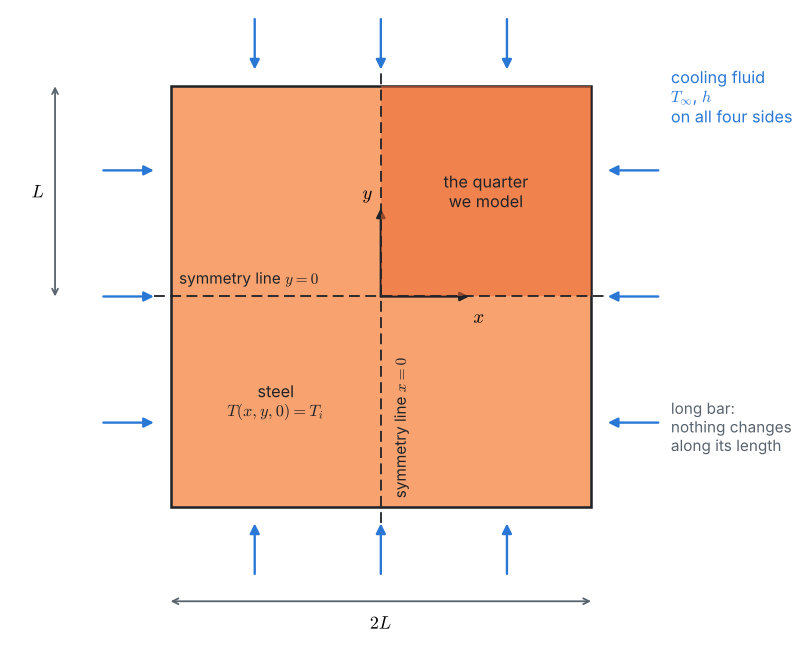

In [4]:
plots.schematic()

---
## Pillar 2 · The grid

**Symmetry.** The billet, its initial temperature and its cooling are symmetric about the two centre lines $x = 0$ and $y = 0$. So no heat crosses these lines ($\partial T/\partial x = 0$ on $x = 0$, $\partial T/\partial y = 0$ on $y = 0$), and it is enough to compute **one quarter**, $0 \le x \le L$, $0 \le y \le L$, with the centre of the billet at the origin. This cuts the number of nodes by four.

We cover the quarter with $N$ intervals in each direction, $\Delta x = \Delta y = L/N$, nodes $(i, j)$ at $x_i = i\,\Delta x$, $y_j = j\,\Delta y$, and store the temperature as rows, `T[j][i]`, as in Problems 6 and 7. Every node is unknown: the surface temperature is not given, it follows from the convection condition.

In [5]:
N = 10                     # intervals per side of the quarter
dx = L / N                 # grid spacing [m] (dy = dx)
x = [i * dx for i in range(N + 1)]
Bi_cell = h * dx / k       # Biot number of one grid cell, appears in the surface equations

print(f"N = {N}: dx = {dx * 1000:.1f} mm, {(N + 1) ** 2} nodes (all unknown)")
print(f"Bi_cell = h dx / k = {Bi_cell:.5f}")

N = 10: dx = 5.0 mm, 121 nodes (all unknown)
Bi_cell = h dx / k = 0.10417


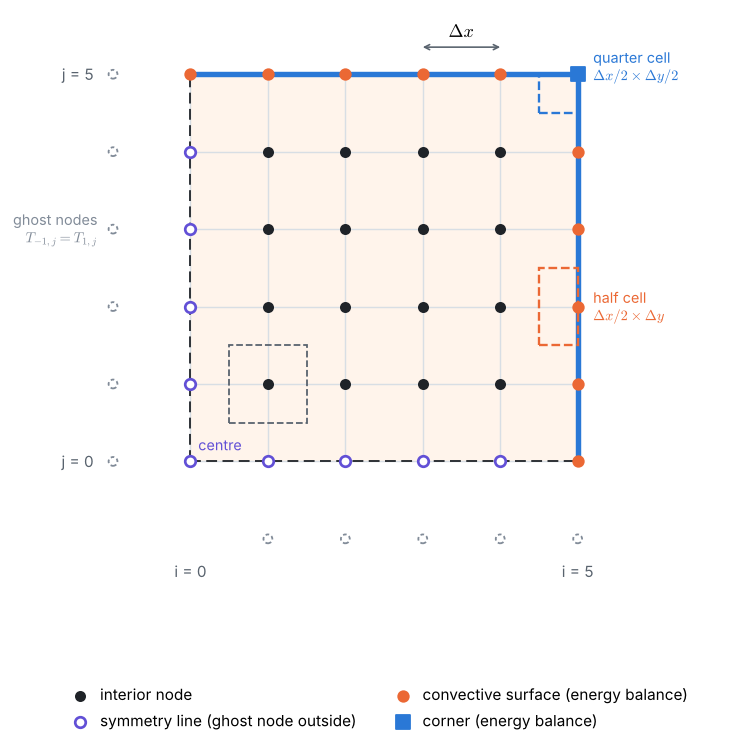

In [6]:
plots.grid(5)

There are four kinds of node: **interior** nodes, nodes on the **symmetry lines** (with a ghost node outside, as in Problem 1), nodes on the **convective surfaces** (half control volumes, as in Problem 4) and the **corner** (a quarter control volume, cooled on two sides). The node on the surface at the end of a symmetry line, $(N, 0)$, is both.

---
## Pillar 3 · Physics: the 2D heat equation and its exact solution

Inside the steel, conduction only:

$$\frac{\partial T}{\partial t} = \alpha\left(\frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2}\right), \qquad 0 < x < L,\; 0 < y < L,\; t > 0,$$

with

| Where | Condition |
|---|---|
| everywhere at $t = 0$ | $T = T_i$ |
| symmetry line $x = 0$ | $\partial T/\partial x = 0$ |
| symmetry line $y = 0$ | $\partial T/\partial y = 0$ |
| surface $x = L$ | $-k\,\partial T/\partial x = h\,(T - T_\infty)$ (heat conducted to the surface = heat convected away) |
| surface $y = L$ | $-k\,\partial T/\partial y = h\,(T - T_\infty)$ |

### The exact solution: a product of two plane walls

For a **plane wall** of half-thickness $L$ (1D, same initial and boundary conditions) the dimensionless temperature $\theta^* = (T - T_\infty)/(T_i - T_\infty)$ is a Fourier series (Incropera et al., §5.5):

$$P(x, t) = \sum_{n=1}^{\infty} C_n\, e^{-\zeta_n^2 Fo}\cos\!\left(\zeta_n \frac{x}{L}\right), \qquad Fo = \frac{\alpha t}{L^2}, \qquad C_n = \frac{4\sin\zeta_n}{2\zeta_n + \sin 2\zeta_n},$$

where the eigenvalues $\zeta_n$ are the positive roots of $\zeta \tan\zeta = Bi$, one in each interval $\big((n-1)\pi,\ (n-\tfrac12)\pi\big)$.

The 2D heat equation separates: if $P(x, t)$ and $P(y, t)$ each solve the 1D problem, their **product** solves the 2D one, with all the boundary conditions above (Incropera et al., §5.8, *product solutions*). The bar of square cross-section is the intersection of two plane walls:

$$\frac{T(x, y, t) - T_\infty}{T_i - T_\infty} = P(x, t)\; P(y, t).$$

We find each root by **bisection** (halving the interval that contains it until it is tiny) and keep 50 terms (more than enough for $t > 0$):

In [7]:
def eigenvalues(Bi, n_terms):
    """The first n_terms positive roots of zeta tan(zeta) = Bi, by bisection."""
    roots = []
    for n in range(n_terms):
        low, high = n * math.pi, n * math.pi + math.pi / 2       # one root in each interval
        for _ in range(60):                           # 60 halvings: 1e-18 of the interval
            mid = (low + high) / 2
            if mid * math.tan(mid) > Bi:
                high = mid
            else:
                low = mid
        roots.append((low + high) / 2)
    return roots


zeta = eigenvalues(Bi, 50)
C_n = [4 * math.sin(z) / (2 * z + math.sin(2 * z)) for z in zeta]


def plane_wall(x, t):
    """Dimensionless temperature of a plane wall, P(x, t) (x measured from the centre)."""
    Fo = alpha * t / L**2
    return sum(c * math.exp(-z * z * Fo) * math.cos(z * x / L) for z, c in zip(zeta, C_n))


def T_exact(x, y, t):
    """Exact temperature in the billet: the product of two plane walls."""
    if t == 0:
        return T_init
    return T_inf + (T_init - T_inf) * plane_wall(x, t) * plane_wall(y, t)


for n in range(3):
    check = zeta[n] * math.tan(zeta[n])
    print(f"zeta_{n + 1} = {zeta[n]:.6f}  (zeta tan zeta = {check:.6f})   C_{n + 1} = {C_n[n]:+.6f}")

zeta_1 = 0.873168  (zeta tan zeta = 1.041667)   C_1 = +1.122485
zeta_2 = 3.435952  (zeta tan zeta = 1.041667)   C_2 = -0.156251
zeta_3 = 6.443461  (zeta tan zeta = 1.041667)   C_3 = +0.048353


When does the centre reach 100 °C? We look for the time with bisection again, this time on $T_{exact}(0, 0, t) - T_{target}$:

In [8]:
def exact_time_to(T_goal, x=0.0, y=0.0):
    """Time at which the exact temperature at (x, y) falls to T_goal (bisection)."""
    low, high = 0.1, 10_000.0
    for _ in range(80):
        mid = (low + high) / 2
        if T_exact(x, y, mid) > T_goal:
            low = mid
        else:
            high = mid
    return (low + high) / 2


t_exact = exact_time_to(T_target)
print(f"exact: the centre reaches {T_target:g} °C after {t_exact:.1f} s ({t_exact / 60:.2f} min)")
print(f"       at that moment the middle of a face is at {T_exact(L, 0, t_exact):.1f} °C "
      f"and the corner at {T_exact(L, L, t_exact):.1f} °C")
print(f"lumped capacitance: {t_lumped:.1f} s, {100 * (t_lumped - t_exact) / t_exact:+.0f} %")

exact: the centre reaches 100 °C after 349.1 s (5.82 min)
       at that moment the middle of a face is at 75.0 °C and the corner at 58.9 °C
lumped capacitance: 230.2 s, -34 %


Lumped capacitance predicts the centre to be cool **a third too early**. A worker who trusted it would pick up a billet whose core is still well above 100 °C.

---
## Pillar 4 · Numerical scheme

### 4a · Explicit FTCS from energy balances

As in Problem 4, put a control volume around each node and write an **energy balance**, now with a storage term: the heat flowing in through all faces raises the temperature of the control volume,

$$\rho\,c_p\,V_{cv}\,\frac{T_P^{n+1} - T_P^n}{\Delta t} = \sum_{\text{faces}} q_{in}^n,$$

with the heat flows evaluated at the **old** time level $n$ (forward in time: explicit). With $r = \alpha\,\Delta t/\Delta x^2$ (the grid Fourier number) and $Bi_{cell} = h\,\Delta x/k$:

**Interior node** (full cell $\Delta x \times \Delta y$):

$$T_P^{n+1} = T_P + r\,(T_E + T_W + T_N + T_S - 4\,T_P).$$

**Node on the convective surface $x = L$** (half cell $\tfrac{\Delta x}{2} \times \Delta y$): conduction from W through a face $\Delta y$ long, from N and S through faces $\Delta x/2$ long, convection through the surface face $\Delta y$:

$$\rho c_p \frac{\Delta x\,\Delta y}{2}\,\frac{T_P^{n+1} - T_P}{\Delta t} = k\,\Delta y\,\frac{T_W - T_P}{\Delta x} + k\,\frac{\Delta x}{2}\,\frac{T_N - T_P}{\Delta y} + k\,\frac{\Delta x}{2}\,\frac{T_S - T_P}{\Delta y} + h\,\Delta y\,(T_\infty - T_P)$$

$$\Longrightarrow\quad T_P^{n+1} = T_P + r\,(2T_W + T_N + T_S - 4\,T_P) + 2\,r\,Bi_{cell}\,(T_\infty - T_P).$$

**Corner** (quarter cell $\tfrac{\Delta x}{2} \times \tfrac{\Delta y}{2}$, conduction from W and S through faces $\Delta x/2$ long, convection through two faces $\Delta x/2$ long):

$$T_P^{n+1} = T_P + 2\,r\,(T_W + T_S - 2\,T_P) + 4\,r\,Bi_{cell}\,(T_\infty - T_P).$$

**Node on a symmetry line** ($x = 0$): the ghost node mirrors the node inside, $T_W = T_E$ (Problem 1), so the interior formula becomes $T_P + r\,(2T_E + T_N + T_S - 4T_P)$. The centre has two ghost nodes.

**One formula for all of them.** Look closely: every one of these energy balances is the sum of an $x$ part and a $y$ part, each of them the 1D second difference of Problem 2 with a ghost node:

| position in a row (or column) | 1D second difference $\delta^2 T$ |
|---|---|
| on the symmetry line ($i = 0$) | $2\,(T_1 - T_0)$ |
| inside | $T_{i+1} - 2T_i + T_{i-1}$ |
| on the cooled surface ($i = N$) | $2\,(T_{N-1} - T_N) - 2\,Bi_{cell}\,T_N + 2\,Bi_{cell}\,T_\infty$ |

The last line is a ghost node too: the convection condition $-k\,(T_{N+1} - T_{N-1})/(2\Delta x) = h\,(T_N - T_\infty)$ fixes the ghost value $T_{N+1}$. So $T_P^{n+1} = T_P + r\,(\delta_x^2 T + \delta_y^2 T)$ at **every** node. We write the second difference once, without the constant $T_\infty$ term, and add that term (the "source") where it belongs:

In [9]:
def second_difference(v, i, N, b):
    """1D second difference at position i of a row or column v, with ghost nodes:
    symmetry at i = 0, convection at i = N (b = Bi_cell; the T_inf part is added separately)."""
    if i == 0:
        return 2 * (v[1] - v[0])
    if i == N:
        return 2 * (v[N - 1] - v[N]) - 2 * b * v[N]
    return v[i + 1] - 2 * v[i] + v[i - 1]


def ftcs_step(T, N, r, b):
    """One explicit (FTCS) time step on the quarter billet; returns a new grid."""
    columns = [[T[j][i] for j in range(N + 1)] for i in range(N + 1)]
    new = [[0.0] * (N + 1) for _ in range(N + 1)]
    for j in range(N + 1):
        for i in range(N + 1):
            change = second_difference(T[j], i, N, b) + second_difference(columns[i], j, N, b)
            if i == N:
                change += 2 * b * T_inf          # convection on the surface x = L
            if j == N:
                change += 2 * b * T_inf          # convection on the surface y = L
            new[j][i] = T[j][i] + r * change
    return new

At the corner both `if` lines apply, which gives exactly the $4\,r\,Bi_{cell}\,T_\infty$ of its energy balance. As in Problem 2, the new values go into a **new** grid.

### 4b · The stability limit, and why the cooled corner makes it stricter

In Problem 2 the explicit update was a **weighted average** of old values, and it stayed well-behaved as long as every weight was positive. Collect the weight of $T_P$ itself in each formula:

| node | weight of $T_P$ | positive if |
|---|---|---|
| interior, symmetry line, centre | $1 - 4r$ | $r \le \dfrac14$ |
| convective surface | $1 - 4r - 2\,r\,Bi_{cell}$ | $r \le \dfrac{1}{2\,(2 + Bi_{cell})}$ |
| corner | $1 - 4r - 4\,r\,Bi_{cell}$ | $r \le \dfrac{1}{4\,(1 + Bi_{cell})}$ |

The **corner** is the strictest: it loses heat through two faces but stores it in only a quarter cell. With all weights positive, every new temperature is an average of old temperatures and $T_\infty$, so it can never leave the range $[T_\infty, T_i]$: no overshoots and no growing errors. This is the stability criterion given by Incropera et al. (Table 5.3):

$$r = \frac{\alpha\,\Delta t}{\Delta x^2} \le \frac{1}{4\,(1 + Bi_{cell})}.$$

In [10]:
def limits(N):
    """The three positive-weight limits of r on a grid with N intervals."""
    b = h * (L / N) / k
    return {"interior": 1 / 4, "surface": 1 / (2 * (2 + b)), "corner": 1 / (4 * (1 + b))}


for n_int in (2, 10):
    d = L / n_int
    lim = limits(n_int)
    print(f"N = {n_int:2d}, dx = {d * 1000:4.1f} mm, Bi_cell = {h * d / k:.4f}:  r <= "
          + ", ".join(f"{name} {value:.4f}" for name, value in lim.items()))
    print(f"        so  dt <= {lim['corner'] * d**2 / alpha:.3f} s")

N =  2, dx = 25.0 mm, Bi_cell = 0.5208:  r <= interior 0.2500, surface 0.1983, corner 0.1644
        so  dt <= 9.397 s
N = 10, dx =  5.0 mm, Bi_cell = 0.1042:  r <= interior 0.2500, surface 0.2376, corner 0.2264
        so  dt <= 0.518 s


Positive weights are a **safe** rule (they guarantee a bounded answer), but they are not the exact boundary of stability. A negative corner weight alone does not yet make errors grow: the explicit method really blows up only when the fastest-changing error pattern (a checkerboard, as in Problem 2's saw-tooth) is amplified at every step. How fast that pattern changes can be found with a few lines of **power iteration**: apply the 1D second difference to a vector again and again; the vector turns into the worst pattern, and the ratio of successive lengths gives its growth factor $\mu$. In 2D the worst pattern is a checkerboard in both directions, so it changes by $1 - 2\,r\,\mu$ per step, and stability needs $r \le 1/\mu$:

In [11]:
def largest_stable_r(N):
    """The true FTCS stability limit, from the worst error pattern (power iteration)."""
    b = h * (L / N) / k
    v = [(-1.0) ** i for i in range(N + 1)]          # start from a saw-tooth
    mu = 0.0
    for _ in range(20_000):
        w = [-second_difference(v, i, N, b) for i in range(N + 1)]
        mu = max(abs(value) for value in w) / max(abs(value) for value in v)
        v = w
        scale = max(abs(value) for value in v)
        v = [value / scale for value in v]           # keep the numbers from growing
    return 1 / mu


for n_int in (2, 10):
    print(f"N = {n_int:2d}: positive weights r <= {limits(n_int)['corner']:.4f},"
          f"  true limit r = {largest_stable_r(n_int):.4f}  (interior: 0.25)")

N =  2: positive weights r <= 0.1644,  true limit r = 0.2293  (interior: 0.25)
N = 10: positive weights r <= 0.2264,  true limit r = 0.2491  (interior: 0.25)


So there are **three** numbers. On the fine grid ($N = 10$) they are close together; on the coarse hand grid ($N = 2$, where $Bi_{cell}$ is five times larger) they are far apart: there even $r = 0.24$, below the interior limit of 1/4, is unstable. In Pillar 6 we test all of this. We keep the safe corner rule for our runs.

### 4c · Implicit methods: Crank–Nicolson and ADI

The time step of FTCS is limited by the grid: halving $\Delta x$ forces $\Delta t$ down by four. An **implicit** method evaluates the heat flows at the **new** time level and has no stability limit. The best known is **Crank–Nicolson**, which averages old and new levels and is second order in time. In 2D, however, every Crank–Nicolson step couples each node to its four neighbours at the new time: a system of $(N+1)^2$ equations with five diagonals, which the Thomas algorithm cannot solve.

**ADI (alternating direction implicit, Peaceman and Rachford, 1955)** splits each time step into two half steps:

1. **implicit in $x$, explicit in $y$:** $\quad T^* - T^n = \tfrac{r}{2}\left(\delta_x^2 T^* + \delta_y^2 T^n\right)$,
2. **explicit in $x$, implicit in $y$:** $\quad T^{n+1} - T^* = \tfrac{r}{2}\left(\delta_x^2 T^* + \delta_y^2 T^{n+1}\right)$,

(plus the constant $T_\infty$ terms on the surfaces in both half steps). In half step 1, the unknowns $T^*$ of one **row** are coupled only to each other, left and right: one **tridiagonal** system per row, solved by the **Thomas algorithm** of Problem 1. Half step 2 does the same for every **column**. Like Crank–Nicolson, ADI is unconditionally stable and second order in time, but each step costs only $2\,(N+1)$ small tridiagonal solves.

Moving the unknowns to the left, each row (or column) gives the system

| position | below the diagonal $a_i$ | diagonal $b_i$ | above the diagonal $c_i$ |
|---|:-:|:-:|:-:|
| $i = 0$ (symmetry) | — | $1 + r$ | $-r$ |
| inside | $-r/2$ | $1 + r$ | $-r/2$ |
| $i = N$ (convection) | $-r$ | $1 + r\,(1 + Bi_{cell})$ | — |

and the same matrix serves every row and every column. The Thomas algorithm, unchanged from Problem 1:

In [12]:
def thomas(a, b, c, r):
    """Solve a tridiagonal system directly (Thomas algorithm)."""
    n = len(b)
    c_star = [0.0] * n
    r_star = [0.0] * n

    # forward sweep: remove the unknown before the diagonal from every equation
    c_star[0] = c[0] / b[0]
    r_star[0] = r[0] / b[0]
    for i in range(1, n):
        denominator = b[i] - a[i] * c_star[i - 1]
        c_star[i] = c[i] / denominator
        r_star[i] = (r[i] - a[i] * r_star[i - 1]) / denominator

    # back substitution
    T = [0.0] * n
    T[n - 1] = r_star[n - 1]
    for i in range(n - 2, -1, -1):
        T[i] = r_star[i] - c_star[i] * T[i + 1]

    return T

In [13]:
def adi_step(T, N, r, b):
    """One ADI (Peaceman-Rachford) time step on the quarter billet; returns a new grid."""
    s = r / 2
    a = [-s] * (N + 1)                    # the tridiagonal matrix, the same for every line
    diag = [1 + 2 * s] * (N + 1)
    c = [-s] * (N + 1)
    c[0] = -2 * s                         # symmetry: ghost node T[-1] = T[1]
    a[N] = -2 * s                         # convection: ghost node from the surface condition
    diag[N] = 1 + 2 * s * (1 + b)
    source = 2 * s * b * T_inf            # the T_inf term of one direction, on the surface

    # half step 1: implicit along each row j, explicit in y
    columns = [[T[j][i] for j in range(N + 1)] for i in range(N + 1)]
    half = []
    for j in range(N + 1):
        rhs = []
        for i in range(N + 1):
            value = T[j][i] + s * second_difference(columns[i], j, N, b)
            if j == N:
                value += source           # y-convection, explicit
            if i == N:
                value += source           # x-convection, implicit side's constant
            rhs.append(value)
        half.append(thomas(a, diag, c, rhs))

    # half step 2: implicit along each column i, explicit in x
    new = [[0.0] * (N + 1) for _ in range(N + 1)]
    for i in range(N + 1):
        rhs = []
        for j in range(N + 1):
            value = half[j][i] + s * second_difference(half[j], i, N, b)
            if i == N:
                value += source
            if j == N:
                value += source
            rhs.append(value)
        column = thomas(a, diag, c, rhs)
        for j in range(N + 1):
            new[j][i] = column[j]
    return new

---
## Pillar 5 · Solution setup

**Initial condition:** $T = T_i = 600$ °C at every node. **Time steps:**

* **FTCS:** the corner rule on $N = 10$ allows $\Delta t \le 0.518$ s. We take $\Delta t = 0.5$ s.
* **ADI:** no stability limit. We take $\Delta t = 10$ s, twenty times larger, and later test other values.

One function marches either method in time and records the temperature at three points: the **centre** $(0, 0)$, the **middle of a face** $(L, 0)$ and the **corner** $(L, L)$, plus full snapshots at chosen times. The time at which the centre reaches 100 °C is found by linear interpolation between the two time steps around it.

In [14]:
def cool(N, dt, t_end, step, snapshot_times=()):
    """March from the uniform initial temperature to t_end with the given step function."""
    dx = L / N
    r = alpha * dt / dx**2
    b = h * dx / k
    T = [[T_init] * (N + 1) for _ in range(N + 1)]
    result = {"r": r, "times": [0.0], "centre": [T_init], "surface middle": [T_init],
              "corner": [T_init], "snapshots": {}}
    for n in range(1, round(t_end / dt) + 1):
        T = step(T, N, r, b)
        t = n * dt
        result["times"].append(t)
        result["centre"].append(T[0][0])
        result["surface middle"].append(T[0][N])
        result["corner"].append(T[N][N])
        for t_snap in snapshot_times:
            if abs(t - t_snap) < 1e-6:
                result["snapshots"][t_snap] = T
    result["T"] = T
    return result


def time_to(result, T_goal):
    """Time at which the centre falls to T_goal (linear interpolation between steps)."""
    t, Tc = result["times"], result["centre"]
    for n in range(1, len(t)):
        if Tc[n] <= T_goal:
            return t[n - 1] + (Tc[n - 1] - T_goal) / (Tc[n - 1] - Tc[n]) * (t[n] - t[n - 1])
    return None

---
## Pillar 6 · Compute

In [15]:
t_end = 600.0
snapshots = (30.0, 120.0, 300.0, 600.0)

start = time.perf_counter()
explicit = cool(N, 0.5, t_end, ftcs_step, snapshots)
time_explicit = time.perf_counter() - start

start = time.perf_counter()
implicit = cool(N, 10.0, t_end, adi_step, snapshots)
time_implicit = time.perf_counter() - start

print(f"centre reaches {T_target:g} °C after:")
for name, res, run_time in (("FTCS, dt = 0.5 s", explicit, time_explicit),
                            ("ADI,  dt = 10 s ", implicit, time_implicit)):
    print(f"  {name}  {time_to(res, T_target):6.1f} s   (r = {res['r']:.4f},"
          f" {len(res['times']) - 1:4d} steps, run time {run_time:.3f} s)")
print(f"  exact             {t_exact:6.1f} s")

centre reaches 100 °C after:
  FTCS, dt = 0.5 s   348.6 s   (r = 0.2187, 1200 steps, run time 0.074 s)
  ADI,  dt = 10 s    349.2 s   (r = 4.3732,   60 steps, run time 0.009 s)
  exact              349.1 s


Both methods agree with the exact time to within a second or so. ADI took 60 steps instead of 1200.

### Breaking the stability limit on purpose

We run FTCS with three values of $r$ on each grid: below the corner rule, between the corner rule and the true limit, and just above the true limit, and follow the corner temperature (the node where trouble starts).

In [16]:
def corner_history(N, r, n_steps):
    """Run FTCS with a given r and return (times, corner temperatures)."""
    dt = r * (L / N) ** 2 / alpha
    res = cool(N, dt, n_steps * dt, ftcs_step)
    return res["times"], res["corner"]


stability_cases = {}
print("corner temperature [°C] after 1, 2, 3, 4 steps, and at the end:")
for n_int, r_values, n_steps in ((2, (0.16, 0.22, 0.24), 60), (10, (0.22, 0.245, 0.255), 300)):
    runs = {}
    for r in r_values:
        times, corner = corner_history(n_int, r, n_steps)
        runs[f"r = {r}"] = (times, corner)
        print(f"N = {n_int:2d}, r = {r:5.3f}, dt = {times[1]:6.3f} s: "
              + " ".join(f"{value:6.1f}" for value in corner[1:5])
              + f"  ... {corner[-1]:8.4g} °C after {n_steps} steps")
    title = (f"N = {n_int}:  corner rule r ≤ {limits(n_int)['corner']:.3f},"
             f"  true limit {largest_stable_r(n_int):.3f}")
    stability_cases[title] = runs

corner temperature [°C] after 1, 2, 3, 4 steps, and at the end:
N =  2, r = 0.160, dt =  9.147 s:  410.0  344.1  301.4  274.4  ...    36.57 °C after 60 steps
N =  2, r = 0.220, dt = 12.577 s:  338.8  312.2  257.9  247.4  ...    31.52 °C after 60 steps
N =  2, r = 0.240, dt = 13.720 s:  315.0  309.3  242.2  246.0  ...     1499 °C after 60 steps
N = 10, r = 0.220, dt =  0.503 s:  547.8  523.3  505.7  492.2  ...    138.1 °C after 300 steps
N = 10, r = 0.245, dt =  0.560 s:  541.8  518.1  500.0  486.3  ...    126.4 °C after 300 steps
N = 10, r = 0.255, dt =  0.583 s:  539.4  516.2  497.8  484.1  ... 1.94e+04 °C after 300 steps


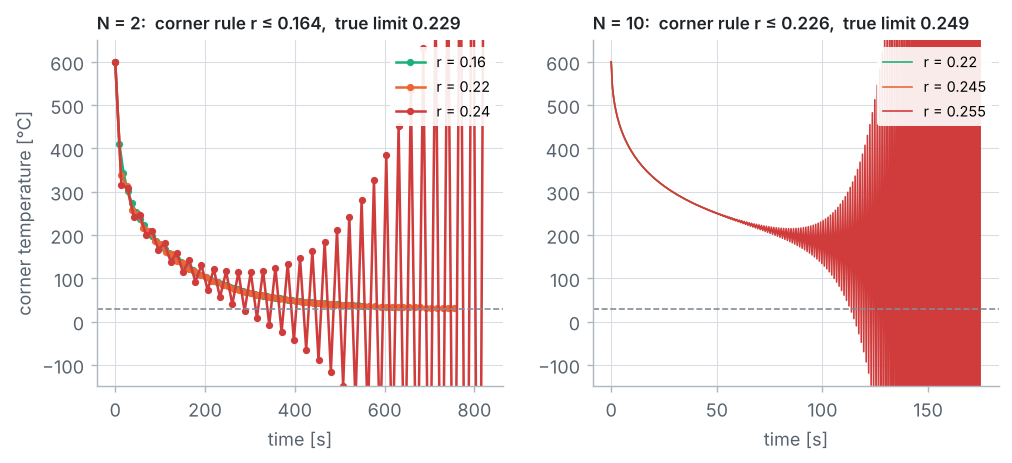

In [17]:
plots.stability(stability_cases, T_inf)

* **Below the corner rule** the corner cools smoothly.
* **Between the two limits** the method is still stable. On the coarse grid ($r = 0.22$) the corner cools in a **staircase**: a large drop, then a small one, then a large one again, because a negative weight makes the new value overshoot in one step and correct in the next. The wiggle dies out, so the answer is still usable, but it is a warning sign. On the fine grid ($r = 0.245$) the corner weight is only slightly negative and the effect is too small to see.
* **Above the true limit** the corner swings up and down with growing amplitude (on the coarse grid it already warms up again in step 4): about 1500 °C after 60 steps on the coarse grid and about 20 000 °C after 300 steps on the fine grid. On the coarse grid this happens at $r = 0.24$, **below** the interior limit of 1/4: the convective corner, not the interior, sets the time step.

The y-axis is clipped at the top and bottom.

### Checking the whiteboard numbers

The whiteboard guide works on the coarsest grid, $N = 2$ (3 × 3 nodes, $\Delta x = 25$ mm), with $r = 0.14$ (just below the corner rule, 0.164), two FTCS steps, and then **one ADI step** five times as long ($r = 0.7$, far beyond the explicit limit). Rows are printed from the top ($j = 2$, the cooled surface) down to the symmetry line ($j = 0$):

In [18]:
def show(T, title):
    """Print a grid row by row, from the top down."""
    print(title)
    for j in range(len(T) - 1, -1, -1):
        print(f"   j = {j}: " + "  ".join(f"{value:8.3f}" for value in T[j]))


N_hand = 2
dx_hand = L / N_hand
b_hand = h * dx_hand / k
r_hand = 0.14
dt_hand = r_hand * dx_hand**2 / alpha
print(f"N = {N_hand}: dx = {dx_hand * 1000:g} mm, Bi_cell = {b_hand:.6f}, r = {r_hand},"
      f" dt = {dt_hand:.4f} s\n")

T_hand = [[T_init] * (N_hand + 1) for _ in range(N_hand + 1)]
hand_states = {"t = 0": T_hand}
for n in (1, 2):
    T_hand = ftcs_step(T_hand, N_hand, r_hand, b_hand)
    hand_states[f"FTCS, {n} step{'s' if n > 1 else ''} (t = {n * dt_hand:.0f} s)"] = T_hand
    show(T_hand, f"FTCS after {n} step(s), t = {n * dt_hand:.2f} s:")

T_ftcs5 = [[T_init] * (N_hand + 1) for _ in range(N_hand + 1)]
for n in range(5):
    T_ftcs5 = ftcs_step(T_ftcs5, N_hand, r_hand, b_hand)
T_adi = adi_step([[T_init] * (N_hand + 1) for _ in range(N_hand + 1)], N_hand, 5 * r_hand, b_hand)
T_ex_hand = [[T_exact(i * dx_hand, j * dx_hand, 5 * dt_hand) for i in range(N_hand + 1)]
             for j in range(N_hand + 1)]
hand_states[f"FTCS, 5 steps (t = {5 * dt_hand:.0f} s)"] = T_ftcs5
hand_states[f"ADI, 1 step (t = {5 * dt_hand:.0f} s)"] = T_adi
hand_states[f"exact (t = {5 * dt_hand:.0f} s)"] = T_ex_hand
show(T_ftcs5, f"\nFTCS after 5 steps, t = {5 * dt_hand:.2f} s:")
show(T_adi, f"ADI after 1 step of {5 * dt_hand:.2f} s (r = {5 * r_hand:.2f}):")
show(T_ex_hand, f"exact solution at the nodes, t = {5 * dt_hand:.2f} s:")

N = 2: dx = 25 mm, Bi_cell = 0.520833, r = 0.14, dt = 8.0033 s

FTCS after 1 step(s), t = 8.00 s:
   j = 2:  516.875   516.875   433.750
   j = 1:  600.000   600.000   516.875
   j = 0:  600.000   600.000   516.875
FTCS after 2 step(s), t = 16.01 s:
   j = 2:  469.147   457.510   362.540
   j = 1:  588.362   576.725   457.510
   j = 0:  600.000   588.362   469.147

FTCS after 5 steps, t = 40.02 s:
   j = 2:  385.993   360.276   267.631
   j = 1:  524.260   488.790   360.276
   j = 0:  562.174   524.260   385.993
ADI after 1 step of 40.02 s (r = 0.70):
   j = 2:  369.598   351.786   247.457
   j = 1:  532.525   506.167   351.786
   j = 0:  560.342   532.525   369.598
exact solution at the nodes, t = 40.02 s:
   j = 2:  386.611   360.859   270.822
   j = 1:  519.939   484.559   360.859
   j = 0:  558.072   519.939   386.611


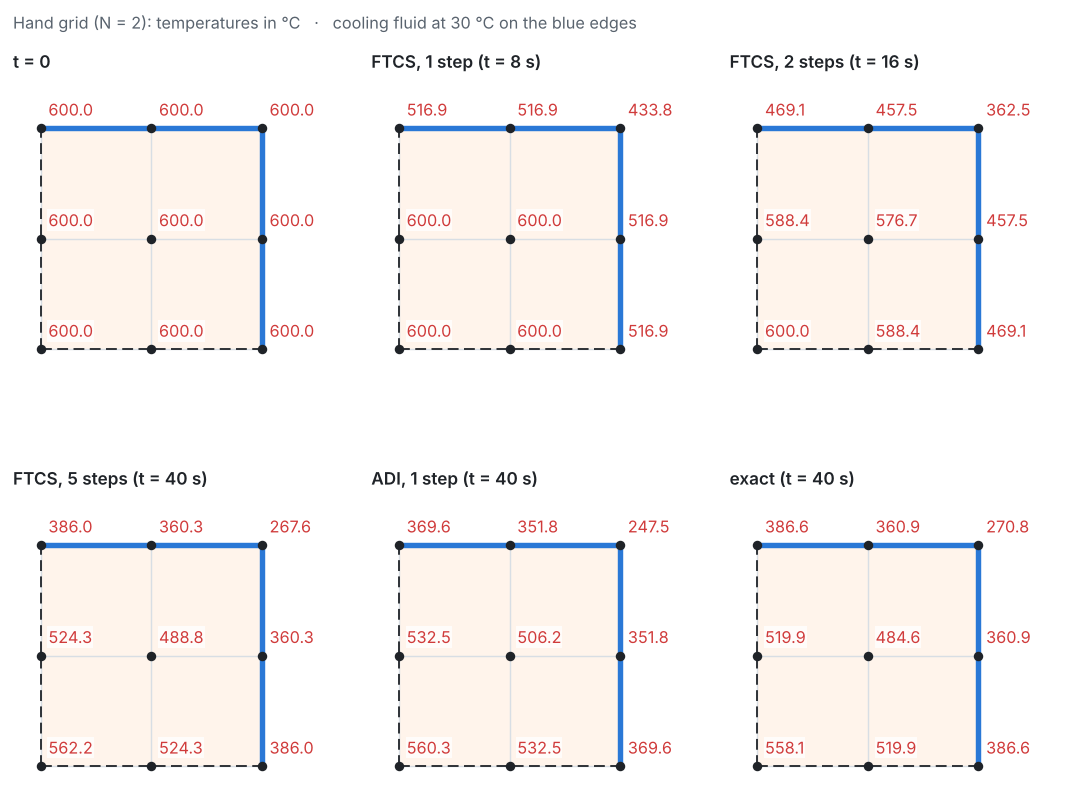

In [19]:
plots.hand_grid(hand_states, T_inf)

---
## Pillar 7 · Post-processing

### Temperature maps

The quarter is mirrored about the two symmetry lines to show the whole cross-section (FTCS, $\Delta t = 0.5$ s):

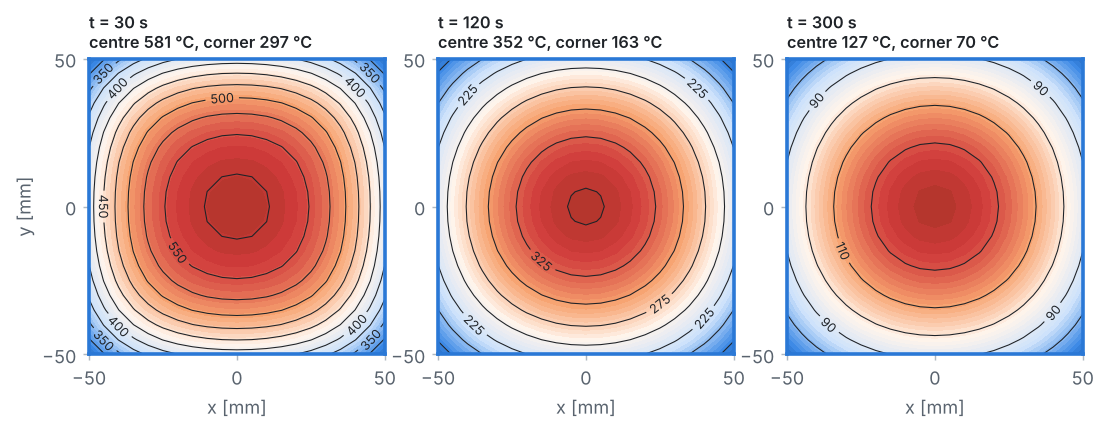

In [20]:
plots.fields(L, {t: explicit["snapshots"][t] for t in (30.0, 120.0, 300.0)})

The isotherms are rounded squares: the corners, cooled from two sides, are always the coldest places, and the centre is always the hottest. After 30 s the outer few millimetres have already lost hundreds of degrees while the centre has not changed at all: heat needs time to diffuse from the centre to the surface.

### Temperature against time, and the lumped-capacitance failure

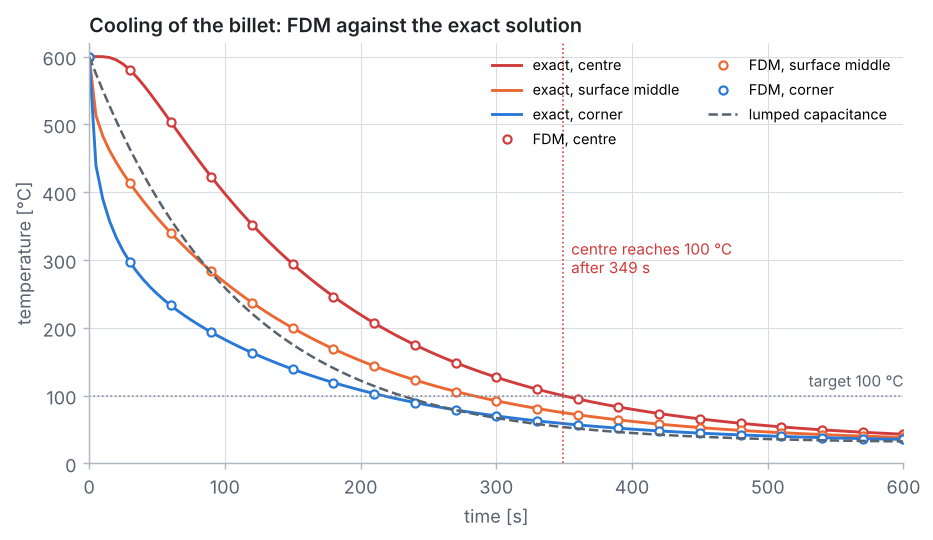

In [21]:
t_fine = [5.0 * n for n in range(1, 121)]
exact_curves = {"centre": [T_exact(0, 0, t) for t in t_fine],
                "surface middle": [T_exact(L, 0, t) for t in t_fine],
                "corner": [T_exact(L, L, t) for t in t_fine]}
every = [n for n, t in enumerate(explicit["times"]) if t % 30 == 0]
fdm_curves = {name: [explicit[name][n] for n in every] for name in exact_curves}
lumped = ([0.0] + t_fine, [T_inf + (T_init - T_inf) * math.exp(-t / tau) for t in [0.0] + t_fine])
plots.history(([explicit["times"][n] for n in every], fdm_curves),
              ([0.0] + t_fine, {name: [T_init] + values for name, values in exact_curves.items()}),
              lumped, T_target, t_exact)

* The **corner** and the **middle of a face** drop quickly at first; the **centre** lags behind, and for the first half minute it does not notice the cooling at all.
* The **lumped-capacitance** curve (one temperature for the whole billet) cuts through the middle: too cold for the centre, too warm for the surface. It reaches 100 °C after 230 s; the centre really needs 349 s.
* The FDM points (FTCS, $\Delta t = 0.5$ s, shown every 30 s) lie on the exact curves.

### Profiles across the billet

Temperature along the symmetry line $y = 0$, from the centre to the middle of a face (FTCS, $\Delta t = 0.5$ s, every second node printed):

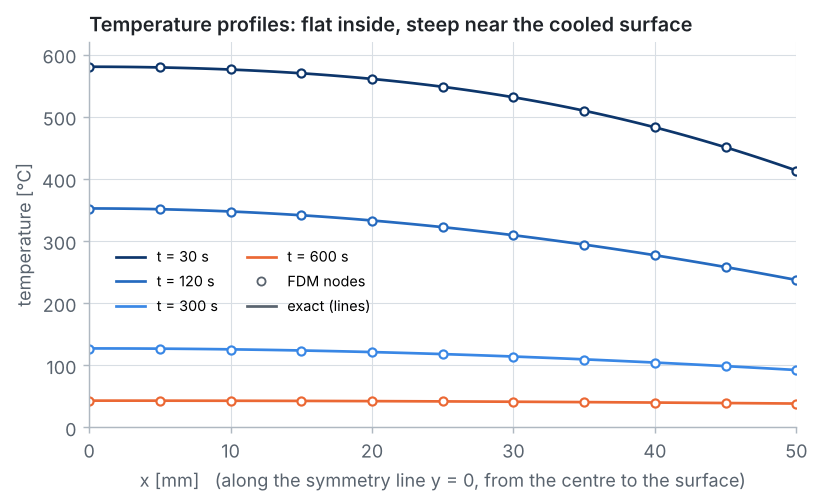

x [mm]     t =  30 s         t = 120 s         t = 300 s         t = 600 s    
           FDM    exact     FDM    exact     FDM    exact     FDM    exact
  0.0    580.73  580.39   352.11  352.36   126.84  127.14    43.05   43.14
 10.0    576.21  575.87   347.23  347.49   125.36  125.67    42.85   42.94
 20.0    561.09  560.79   332.74  333.00   120.99  121.28    42.26   42.35
 30.0    531.46  531.25   309.04  309.31   113.84  114.11    41.30   41.38
 40.0    482.94  482.86   276.82  277.09   104.14  104.39    39.99   40.06
 50.0    413.28  413.35   237.03  237.30    92.18   92.41    38.38   38.44


In [22]:
profile_times = (30.0, 120.0, 300.0, 600.0)
x_mm = [1000 * xi for xi in x]
numerical_profiles = {t: explicit["snapshots"][t][0] for t in profile_times}  # row j = 0: y = 0
x_dense = [L * m / 100 for m in range(101)]
exact_profiles = {t: ([1000 * xi for xi in x_dense], [T_exact(xi, 0, t) for xi in x_dense])
                  for t in profile_times}
plots.profiles(x_mm, numerical_profiles, exact_profiles)

print("x [mm]" + "".join(f"     t = {t:3.0f} s    " for t in profile_times))
print("      " + "     FDM    exact" * len(profile_times))
for i in range(0, N + 1, 2):
    print(f"{x_mm[i]:5.1f} " + "".join(f"  {numerical_profiles[t][i]:7.2f} {T_exact(x[i], 0, t):7.2f}"
                                       for t in profile_times))

Inside the billet the profiles are flat (a cosine, the first term of the series); near the cooled surface they are steep, and the surface temperature lies well above $T_\infty$: the steel cannot conduct heat to the surface as fast as the fluid could carry it away. That temperature drop inside the steel is exactly what lumped capacitance ignores. The largest differences from the exact solution are at the surface at early times, when the temperature changes fastest there.

### Cost against accuracy

Now the main comparison. We run FTCS at its largest safe time step and ADI with time steps up to 120 times larger, all on the same grid ($N = 10$), and compare the centre temperature at $t = 300$ s and the time to reach 100 °C with the exact values. (Run times depend on your computer; the ratios are what matter.)

In [23]:
runs = [("FTCS", ftcs_step, 0.5)] + [("ADI", adi_step, dt) for dt in (5.0, 10.0, 20.0, 30.0, 60.0)]
T_exact_300 = T_exact(0, 0, 300.0)
comparison = []
print("                                         centre at 300 s      reaches 100 °C")
print("method  dt [s]      r   steps  time [s]   T [°C]    error      t [s]   error")
for name, step, dt in runs:
    start = time.perf_counter()
    res = cool(N, dt, t_end, step)
    run_time = time.perf_counter() - start
    T300 = res["centre"][round(300 / dt)]
    t_goal = time_to(res, T_target)
    comparison.append({"method": name, "dt": dt, "r": res["r"], "steps": len(res["times"]) - 1,
                       "T_centre_300": T300, "time_to_target": t_goal})
    print(f"{name:6s} {dt:6.1f} {res['r']:7.3f} {len(res['times']) - 1:6d} {run_time:8.3f}"
          f"  {T300:8.3f}  {T300 - T_exact_300:+7.3f}   {t_goal:7.1f}  {t_goal - t_exact:+5.1f}")
print(f"exact                                   {T_exact_300:8.3f}             {t_exact:7.1f}")

                                         centre at 300 s      reaches 100 °C
method  dt [s]      r   steps  time [s]   T [°C]    error      t [s]   error
FTCS      0.5   0.219   1200    0.057   126.838   -0.306     348.6   -0.6
ADI       5.0   2.187    120    0.015   127.158   +0.014     349.2   +0.0
ADI      10.0   4.373     60    0.008   127.144   +0.000     349.2   +0.0
ADI      20.0   8.746     30    0.004   127.091   -0.053     349.4   +0.2
ADI      30.0  13.120     20    0.003   127.001   -0.143     349.6   +0.4
ADI      60.0  26.239     10    0.001   125.507   -1.637     350.1   +0.9
exact                                    127.144               349.1


* One ADI step costs several times more than one FTCS step (two Thomas solves per line instead of one formula per node), but ADI needs **far fewer** steps.
* ADI with $\Delta t = 5$ s is about **20 times more accurate** than FTCS with $\Delta t = 0.5$ s at the centre, and several times cheaper. FTCS is first order in time: on this grid its error comes almost entirely from $\Delta t$, not from $\Delta x$. ADI is second order.
* The tiny ADI errors at $\Delta t = 5$ and 10 s are partly luck: the spatial error of the grid ($+0.018$ °C at the centre, see Verification 2) and the time error have opposite signs and cancel.
* With $\Delta t = 60$ s the centre is 1.6 °C too cold at 300 s, although the time to reach 100 °C is still within a second. Stability is not accuracy: the step must still resolve the physics.

What happens near the surface, where the temperature changes fastest at the start?

corner temperature [°C] after 1, 2, 3, 4 steps
dt =  10.0 s   ADI:  346.6  354.9  282.1  280.1    exact:  390.1  333.0  297.0  270.9
dt =  60.0 s   ADI:  146.8  220.0   87.8  115.8    exact:  233.2  163.3  119.2   89.8
dt = 120.0 s   ADI:   77.2  153.1   35.4   63.0    exact:  163.3   89.8   56.9   42.1


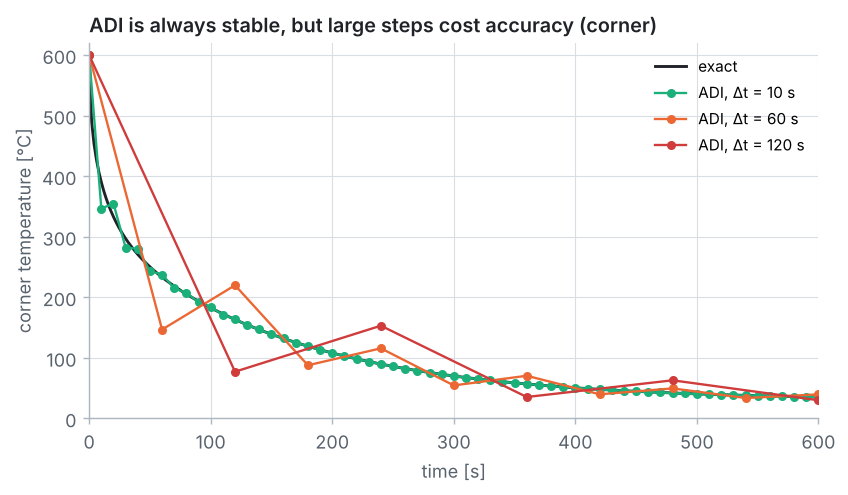

In [24]:
large_runs = {}
print("corner temperature [°C] after 1, 2, 3, 4 steps")
for dt in (10.0, 60.0, 120.0):
    res = cool(N, dt, t_end, adi_step)
    large_runs[f"ADI, Δt = {dt:g} s"] = (res["times"], res["corner"])
    print(f"dt = {dt:5.1f} s   ADI: " + " ".join(f"{value:6.1f}" for value in res["corner"][1:5])
          + "    exact: " + " ".join(f"{T_exact(L, L, n * dt):6.1f}" for n in range(1, 5)))
t_dense = [0.0] + [2.0 * n for n in range(1, 301)]
plots.adi_large_steps(large_runs, (t_dense, [T_exact(L, L, t) for t in t_dense]), "corner")

With large steps the corner temperature **oscillates**: it drops too far, then rises again (the corner of a cooling billet cannot get warmer!). Even $\Delta t = 10$ s gets the first steps at the corner wrong by more than 40 °C. ADI, like Crank–Nicolson, damps the fastest-changing patterns only weakly when $r$ is large ($r = 52$ for $\Delta t = 120$ s), so the sudden start of cooling at the corner rings for a few steps. The oscillation decays, and the centre, far from the corner, is hardly affected, but it is a reminder to choose $\Delta t$ for **accuracy** even when stability does not limit it: small steps at the start, when the surface changes fastest, larger steps later. (Commercial codes such as COMSOL adapt their time step automatically for exactly this reason.)

### Verification 1: refining the grid

FTCS with $r = 0.2$ on four grids, error against the exact solution at $t = 300$ s (largest error over all nodes). Because $r$ is fixed, $\Delta t$ shrinks with $\Delta x^2$: both error sources shrink by four when $\Delta x$ halves. **The finest grid takes several seconds**: halving $\Delta x$ multiplies the work of FTCS by 16 (four times the nodes, four times the steps).

In [25]:
grid_study = {"dx": [], "max_error": [], "centre_error": []}
print("   N  dx [mm]   dt [s]   steps  time [s]   largest error [°C]  ratio  centre error [°C]")
for n_int in (5, 10, 20, 40):
    d = L / n_int
    n_steps = math.ceil(300 / (0.2 * d**2 / alpha))     # r close to 0.2, ending exactly at 300 s
    dt = 300 / n_steps
    start = time.perf_counter()
    res = cool(n_int, dt, 300.0, ftcs_step)
    run_time = time.perf_counter() - start
    error = max(abs(res["T"][j][i] - T_exact(i * d, j * d, 300.0))
                for j in range(n_int + 1) for i in range(n_int + 1))
    ratio = f"{grid_study['max_error'][-1] / error:5.2f}" if grid_study["max_error"] else "     "
    grid_study["dx"].append(d * 1000)
    grid_study["max_error"].append(error)
    grid_study["centre_error"].append(res["T"][0][0] - T_exact(0, 0, 300.0))
    print(f"{n_int:4d}  {d * 1000:6.2f}  {dt:7.4f}  {n_steps:6d}  {run_time:8.2f}"
          f"   {error:14.5f}     {ratio}   {grid_study['centre_error'][-1]:+12.5f}")

   N  dx [mm]   dt [s]   steps  time [s]   largest error [°C]  ratio  centre error [°C]
   5   10.00   1.8293     164      0.00          1.11765                 -1.11765


  10    5.00   0.4573     656      0.06          0.27848      4.01       -0.27848


  20    2.50   0.1143    2624      0.49          0.06956      4.00       -0.06956


  40    1.25   0.0286   10496      6.83          0.01739      4.00       -0.01739


The error drops by a factor of 4 each time $\Delta x$ is halved: **second order**, as expected from central differences in space (and $\Delta t \propto \Delta x^2$ for FTCS).

### Verification 2: refining the time step

To see the time error alone, we keep the grid fixed ($N = 10$) and compare with a run on the same grid with a tiny time step (ADI, $\Delta t = 0.05$ s), so that the spatial error cancels:

In [26]:
reference = cool(N, 0.05, 300.0, adi_step)["centre"][-1]
time_study = {"FTCS": ([], []), "ADI": ([], [])}
print(f"reference (same grid, ADI dt = 0.05 s): centre at 300 s = {reference:.5f} °C")
print("method   dt [s]    time error [°C]   ratio")
for name, step, dts in (("FTCS", ftcs_step, (0.5, 0.25, 0.125, 0.0625)),
                        ("ADI", adi_step, (60.0, 30.0, 15.0, 7.5, 3.75))):
    for dt in dts:
        error = abs(cool(N, dt, 300.0, step)["centre"][-1] - reference)
        errs = time_study[name][1]
        ratio = f"{errs[-1] / error:5.2f}" if errs else ""
        time_study[name][0].append(dt)
        errs.append(error)
        print(f"{name:6s}  {dt:7.4f}       {error:10.6f}      {ratio}")

reference (same grid, ADI dt = 0.05 s): centre at 300 s = 127.16214 °C
method   dt [s]    time error [°C]   ratio
FTCS     0.5000         0.324405      
FTCS     0.2500         0.162157       2.00
FTCS     0.1250         0.081067       2.00


FTCS     0.0625         0.040531       2.00
ADI     60.0000         1.654798      
ADI     30.0000         0.161481      10.25
ADI     15.0000         0.040478       3.99
ADI      7.5000         0.010135       3.99
ADI      3.7500         0.002533       4.00


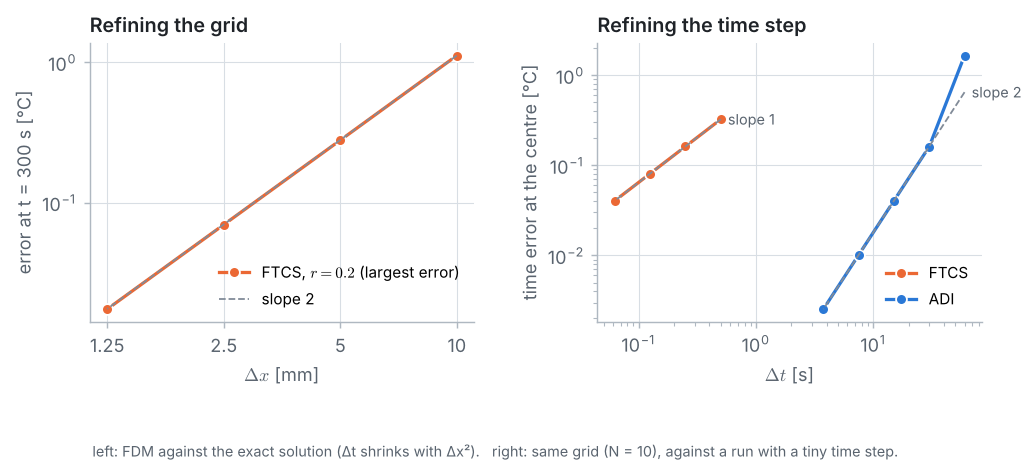

In [27]:
plots.convergence((grid_study["dx"], grid_study["max_error"]), time_study)

* **FTCS:** halving $\Delta t$ halves the error: **first order** in time.
* **ADI:** halving $\Delta t$ divides the error by about 4: **second order** in time, like Crank–Nicolson. (Only from 60 s to 30 s does the error drop by 10: a 60 s step is too large for the error to follow the $C\,\Delta t^2$ law yet.)

So for the same accuracy ADI can take much larger steps, and its advantage grows on finer grids, where the FTCS step must shrink with $\Delta x^2$.

### Numbers for the COMSOL comparison

The last cell saves the reference numbers (exact solution, FTCS and ADI on $N = 10$) used to compare with a COMSOL model of the same billet in `comsol_solution/fdm_reference.json`.

In [28]:
output_times = [30.0, 60.0, 120.0, 180.0, 240.0, 300.0, 360.0, 420.0, 480.0, 540.0, 600.0]
points = {"centre": (0.0, 0.0), "surface middle": (L, 0.0), "corner": (L, L)}
node_of = {"centre": (0, 0), "surface middle": (0, N), "corner": (N, N)}
ftcs_index = {t: round(t / 0.5) for t in output_times}
adi_index = {t: round(t / 10.0) for t in output_times}
reference_numbers = {
    "description": "Problem 8 (cooling a steel billet): reference numbers for the COMSOL comparison, "
                   "written by 03_fdm_solver.ipynb. Temperatures in degC, times in s, lengths in m. "
                   "Points: centre (0, 0), surface middle (L, 0), corner (L, L) of the quarter model.",
    "data": {"L_half_width_m": L, "T_initial_C": T_init, "T_inf_C": T_inf, "h_W_m2K": h,
             "k_W_mK": k, "rho_kg_m3": rho, "cp_J_kgK": c_p, "alpha_m2_s": alpha,
             "Bi_hL_over_k": Bi, "Bi_lumped_hLc_over_k": Bi_lumped, "T_target_C": T_target},
    "eigenvalues_zeta": zeta[:6], "coefficients_C": C_n[:6],
    "time_to_target_s": {"exact": t_exact, "lumped_capacitance": t_lumped,
                         "FTCS_N10_dt0.5": time_to(explicit, T_target), "ADI_N10_dt10": time_to(implicit, T_target)},
    "point_histories": {
        "times_s": output_times,
        "exact": {name: [T_exact(*xy, t) for t in output_times] for name, xy in points.items()},
        "FTCS_N10_dt0.5": {name: [explicit[name][ftcs_index[t]] for t in output_times] for name in points},
        "ADI_N10_dt10": {name: [implicit[name][adi_index[t]] for t in output_times] for name in points}},
    "profiles_y0": {"x_m": [L * m / 10 for m in range(11)],
                    "times_s": list(profile_times),
                    "exact": {str(t): [T_exact(L * m / 10, 0, t) for m in range(11)] for t in profile_times},
                    "FTCS_N10_dt0.5": {str(t): explicit["snapshots"][t][0] for t in profile_times},
                    "ADI_N10_dt10": {str(t): implicit["snapshots"][t][0] for t in profile_times}},
    "cost_accuracy_N10": comparison,
    "grid_study_FTCS_r0.2_t300": grid_study,
    "time_study_N10_t300": {"reference_centre_C": reference,
                            "FTCS": dict(zip(("dt_s", "error_C"), time_study["FTCS"])),
                            "ADI": dict(zip(("dt_s", "error_C"), time_study["ADI"]))},
    "stability_limits_r": {str(n_int): dict(limits(n_int), true=largest_stable_r(n_int)) for n_int in (2, 10)},
}
with open("comsol_solution/fdm_reference.json", "w", encoding="utf-8") as f:
    json.dump(reference_numbers, f, indent=1)
print("saved comsol_solution/fdm_reference.json")

saved comsol_solution/fdm_reference.json


---
## Summary

* $Bi = hL_c/k \approx 0.52 \gg 0.1$: **lumped capacitance fails**. It predicts that the centre reaches 100 °C after 230 s; it really takes 349 s.
* **Symmetry** reduces the billet to one quarter, with ghost nodes on the symmetry lines; the cooled surfaces get their node equations from **energy balances** on half and quarter control volumes.
* Every node equation is the sum of an $x$ and a $y$ second difference. **FTCS** is simple, but its time step is limited by the **cooled corner**: $r \le 1/[4(1 + Bi_{cell})]$ keeps all weights positive. Beyond the true limit (between that value and 1/4) the solution explodes.
* **ADI** turns each implicit step into two sets of tridiagonal systems, solved by the **Thomas algorithm** of Problem 1. It is unconditionally stable and second order in time: with $\Delta t = 5$ s it beats FTCS at $\Delta t = 0.5$ s in both accuracy and cost.
* The **exact product solution** (two plane walls) verifies both methods: second order in $\Delta x$; first order (FTCS) and second order (ADI) in $\Delta t$.

## Try it yourself

1. Change `h` to 100 W/(m²·K) (air blast). What is $Bi_{L_c}$ now? Is lumped capacitance acceptable? How long does the centre take to reach 100 °C?
2. Change `h` to 5000 W/(m²·K) (an intense water quench). How do the corner rule and the FTCS time step change? Does ADI care?
3. Make the billet rectangular, $2L_x \times 2L_y$ with $L_y = 2L_x$. Which lines change? (Hint: $r_x \ne r_y$, and the exact solution becomes $P_x(x, t)\,P_y(y, t)$ with two Biot numbers.)
4. Replace ADI by a **fully implicit** (backward Euler) step solved by Gauss–Seidel iterations (Problem 3). How many iterations does each step need, and how does the cost compare with ADI?
5. *Challenge:* steel properties depend on temperature ($k$ falls from 60.5 W/(m·K) at 300 K to 30 W/(m·K) at 1000 K). Use $k(T)$ in the explicit method, evaluated at the old time level. How much does the time to 100 °C change?